# 03 · Base pour tester une métaheuristique

Ce notebook montre comment écrire, lancer et comparer des algorithmes avec le paquet `optimizer`.

**Une métaheuristique est une fonction :**

```python
def my_algorithm(problem, rng, **params):
    ...
```

- `problem.fitness(mapping)` ou `problem.fitness_of(permutation)` : vraie fitness, coûte **1 évaluation**. Quand le budget est épuisé, une exception `BudgetExhausted` arrête l'algorithme ; inutile de la gérer toi-même.
- `problem.surrogate(mapping)` ou `problem.surrogate_of(permutation)` : coût de distance, **gratuit**.
- `problem.best_cost`, `problem.best_mapping`, `problem.evaluations`, `problem.remaining` : suivis automatiquement.
- `rng` : générateur aléatoire NumPy, initialisé avec la graine de l'exécution (reproductible).

**Représentation conseillée :** une permutation de `range(m)` dont les `n` premiers éléments forment le placement. Un échange `(i, j)` avec `i < n ≤ j` déplace un qubit logique vers un qubit physique libre. Les outils sont dans `optimizer.representation` : `random_permutation`, `swap`, `random_swap`, `swap_moves`, `to_mapping`, `from_mapping`.

In [1]:
import numpy as np
import pandas as pd

from goc.paths import RESULTS_ROOT
# Lancement d'exécutions, tableaux de résultats, sauvegarde, écriture des fichiers solutions.
from optimizer import history_frame, results_frame, run_algorithm, run_grid, save_results, write_result_if_better
# Deux algorithmes de référence fournis.
from optimizer.algorithms import identity, random_search
from optimizer.representation import random_permutation

# Nom de ton groupe, utilisé dans le nom des fichiers solutions (GroupeX_Challenge_N.txt).
GROUP = "Groupe0"

In [2]:
# Réglages communs des graphiques : couleurs, polices, grilles.
import matplotlib as mpl
import matplotlib.pyplot as plt

# Palette de couleurs utilisée pour les séries (une couleur par algorithme ou par instance).
PALETTE = ["#3d72c4", "#d4692b", "#2a8a4f", "#c9443c", "#7a5cc2", "#8a8f98", "#c48a0a", "#2a9fb0", "#b04a8f"]
# Couleurs du cours : orange pour les qubits logiques, bleu pour les qubits physiques.
LOGICAL, LOGICAL_SOFT = "#d4692b", "#fdefe6"
PHYSICAL, PHYSICAL_SOFT = "#3d72c4", "#dfe8f5"
# Couleur selon la distance sur la puce : vert = voisins, jaune = distance 2, rouge = distance 3 ou plus.
DISTANCE_COLORS = {1: "#2a8a4f", 2: "#c48a0a", 3: "#c9443c"}
# Gris pour les textes secondaires et les grilles.
MUTED, GRID = "#656d76", "#e1e4e8"

# Application du style à tous les graphiques matplotlib du notebook.
mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def subplot_grid(count, cols=3, width=4.4, height=3.0):
    """Crée une grille de `count` petits graphiques (cols par ligne) et cache les cases inutilisées."""
    # Nombre de lignes nécessaires (division arrondie au supérieur).
    rows = -(-count // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * width, rows * height), squeeze=False)
    # Les cases en trop (dernière ligne incomplète) sont masquées.
    for ax in axes.ravel()[count:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:count]

## Fonctions d'analyse

- `display_table` : une cellule `moyenne ± écart-type (meilleur)` par algorithme et par instance ;
- `comparison_table` : les mêmes statistiques en colonnes numériques ;
- `plot_convergence` : meilleur coût trouvé en fonction du nombre d'évaluations (moyenne sur les graines, bande = min/max) ;
- `plot_result_boxplots` : distribution du meilleur coût final sur les graines.

In [3]:
def display_table(frame, value="best_cost"):
    """Tableau lisible : pour chaque algorithme (ligne) et instance (colonne), « moyenne ± écart-type (meilleur) »."""
    cells = frame.groupby(["algorithm", "instance_id"], sort=False)[value].agg(lambda s: f"{s.mean():.1f} ± {s.std(ddof=0):.1f} ({s.min():g})")
    # unstack met les instances en colonnes ; les noms de colonnes deviennent « inst. N ».
    return cells.unstack("instance_id").rename(columns=lambda c: f"inst. {c}")


def comparison_table(frame, value="best_cost"):
    """Mêmes statistiques en valeurs numériques, une colonne par (instance, statistique)."""
    table = frame.groupby(["algorithm", "instance_id"])[value].agg(["mean", "std", "min", "count"]).round(2)
    table = table.unstack("instance_id").swaplevel(0, 1, axis=1).sort_index(axis=1)
    # Colonnes à un seul niveau, par ex. « inst. 3 · mean », plus simples à lire et à manipuler.
    table.columns = [f"inst. {instance} · {stat}" for instance, stat in table.columns]
    return table


def plot_convergence(history, instance_ids=None):
    """Meilleur coût trouvé en fonction du nombre d'évaluations, par instance (moyenne sur les graines, bande min/max)."""
    instance_ids = instance_ids or sorted(history["instance_id"].unique())
    fig, axes = subplot_grid(len(instance_ids), cols=min(3, len(instance_ids)), width=4.6, height=3.2)
    for ax, instance_id in zip(axes, instance_ids):
        subset = history[history["instance_id"] == instance_id]
        for color, (algorithm, group) in zip(PALETTE * 2, subset.groupby("algorithm")):
            # Une colonne par graine, une ligne par numéro d'évaluation ; ffill complète les trous.
            curves = group.pivot_table(index="evaluation", columns="seed", values="best").ffill()
            ax.plot(curves.index, curves.mean(axis=1), color=color, label=algorithm, linewidth=1.5)
            ax.fill_between(curves.index, curves.min(axis=1), curves.max(axis=1), color=color, alpha=0.15)
        ax.set_title(f"Instance {instance_id}")
        ax.set_xlabel("evaluations", fontsize=8)
        ax.set_ylabel("best fitness so far", fontsize=8)
        ax.legend()
    fig.suptitle("Convergence: mean over seeds, band = min/max", y=1.0)
    fig.tight_layout()
    return fig


def plot_result_boxplots(frame):
    """Boîtes à moustaches du meilleur coût final de chaque algorithme (une boîte = toutes les graines)."""
    instance_ids = sorted(frame["instance_id"].unique())
    fig, axes = subplot_grid(len(instance_ids), cols=min(3, len(instance_ids)), width=4.2, height=3.0)
    for ax, instance_id in zip(axes, instance_ids):
        subset = frame[frame["instance_id"] == instance_id]
        algorithms = sorted(subset["algorithm"].unique())
        ax.boxplot([subset.loc[subset["algorithm"] == a, "best_cost"] for a in algorithms], widths=0.5, medianprops={"color": LOGICAL})
        ax.set_xticks(range(1, len(algorithms) + 1), algorithms, rotation=20, fontsize=8)
        ax.set_title(f"Instance {instance_id}")
        ax.set_ylabel("best fitness", fontsize=8)
    fig.suptitle("Final best fitness over seeds", y=1.0)
    fig.tight_layout()
    return fig

## 1. Une exécution

`run_algorithm(algorithm, instance_id, budget, seed)` crée le problème, lance l'algorithme jusqu'à épuisement du budget, et renvoie un `Result` : meilleur placement, meilleur coût, historique, temps.

In [4]:
# Recherche aléatoire sur l'instance 3, 60 vraies évaluations, graine 0.
result = run_algorithm(random_search.run, instance_id=3, budget=60, seed=0)
# Résumé de l'exécution (dictionnaire).
result.summary()

{'algorithm': 'random_search',
 'instance_id': 3,
 'seed': 0,
 'best_mapping': [1, 3, 15, 5, 8, 13, 6, 7, 4, 10],
 'best_cost': 155,
 'evaluations': 60,
 'seconds': 5.858412500005215,
 'params': {}}

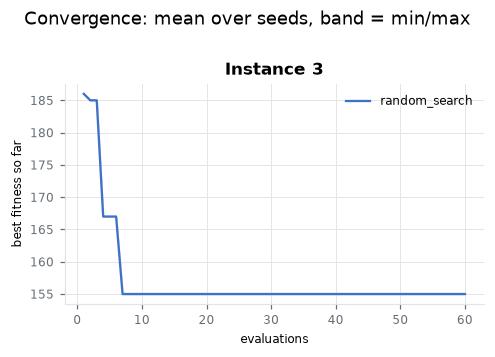

In [5]:
# Courbe de convergence de cette exécution unique.
plot_convergence(history_frame([result]));

## 2. Écrire son propre algorithme

Exemple simple qui combine les deux fonctions de coût : on tire 200 placements aléatoires, on garde celui dont le coût de distance est le plus faible, et on l'évalue avec la vraie fitness. On recommence jusqu'à la fin du budget. C'est aussi une des références à battre.

In [6]:
def surrogate_filtered_random(problem, rng, candidates=200):
    """Boucle : tirer `candidates` placements, n'évaluer que le meilleur selon le coût de distance (gratuit)."""
    while True:
        pool = [random_permutation(problem.m, rng) for _ in range(candidates)]
        # Seule la permutation de plus petit coût de distance consomme une vraie évaluation.
        problem.fitness_of(min(pool, key=problem.surrogate_of))

## 3. Comparer plusieurs algorithmes

`run_grid` lance chaque algorithme sur chaque instance avec plusieurs graines, **à budget égal**. Ici le budget est petit pour que la démonstration reste rapide ; pour une vraie comparaison, prends au moins 500 évaluations et 10 graines.

`identity` évalue le placement identité à chaque fois : son « meilleur » est le minimum de N tirages du bruit, ce qui en fait une référence honnête.

In [7]:
# Algorithmes comparés : {nom: (fonction, paramètres)}.
ALGORITHMS = {
    "identity": (identity.run, {}),
    "random_search": (random_search.run, {}),
    "surrogate_filtered": (surrogate_filtered_random, {"candidates": 200}),
}
INSTANCES = [3, 6, 9]
SEEDS = [0, 1, 2]
BUDGET = 40

# 3 algorithmes × 3 instances × 3 graines = 27 exécutions de 40 évaluations.
results = run_grid(ALGORITHMS, INSTANCES, SEEDS, BUDGET)

[2/27] 7 s | last: identity, instance 3, seed 1 -> 144


[4/27] 12 s | last: identity, instance 6, seed 0 -> 83


[6/27] 15 s | last: identity, instance 6, seed 2 -> 83


[8/27] 19 s | last: identity, instance 9, seed 1 -> 137


[10/27] 25 s | last: random_search, instance 3, seed 0 -> 153


[12/27] 31 s | last: random_search, instance 3, seed 2 -> 157


... (4 outputs left out)

[22/27] 55 s | last: surrogate_filtered, instance 6, seed 0 -> 41


[24/27] 58 s | last: surrogate_filtered, instance 6, seed 2 -> 38


[26/27] 63 s | last: surrogate_filtered, instance 9, seed 1 -> 109


[27/27] 65 s | last: surrogate_filtered, instance 9, seed 2 -> 107


In [8]:
# Une ligne par exécution, puis le tableau comparatif lisible.
frame = results_frame(results)
summary_table = display_table(frame)
summary_table

instance_id,inst. 3,inst. 6,inst. 9
algorithm,,,
identity,142.0 ± 1.4 (141),81.0 ± 2.8 (77),137.0 ± 0.0 (137)
random_search,153.3 ± 2.9 (150),46.0 ± 3.3 (42),103.7 ± 2.1 (101)
surrogate_filtered,142.7 ± 9.7 (129),39.0 ± 1.4 (38),105.3 ± 3.9 (100)


In [9]:
# Les mêmes statistiques en colonnes numériques (utile pour d'autres calculs).
numeric_table = comparison_table(frame)
numeric_table

,inst. 3 · count,inst. 3 · mean,inst. 3 · min,inst. 3 · std,inst. 6 · count,inst. 6 · mean,inst. 6 · min,inst. 6 · std,inst. 9 · count,inst. 9 · mean,inst. 9 · min,inst. 9 · std
algorithm,,,,,,,,,,,,
identity,3,142.00,141,1.73,3,81.0,77,3.46,3,137.00,137,0.00
random_search,3,153.33,150,3.51,3,46.0,42,4.00,3,103.67,101,2.52
surrogate_filtered,3,142.67,129,11.93,3,39.0,38,1.73,3,105.33,100,4.73


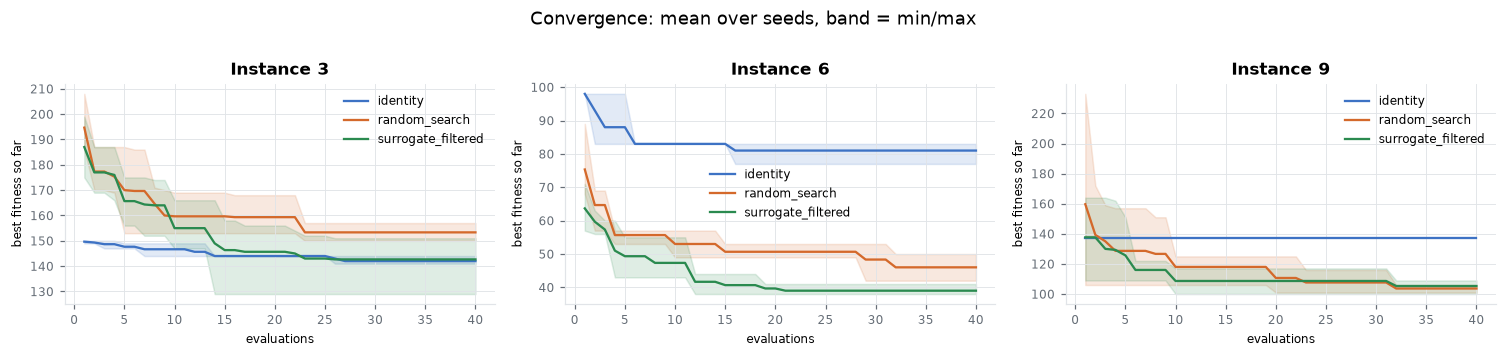

In [10]:
plot_convergence(history_frame(results));

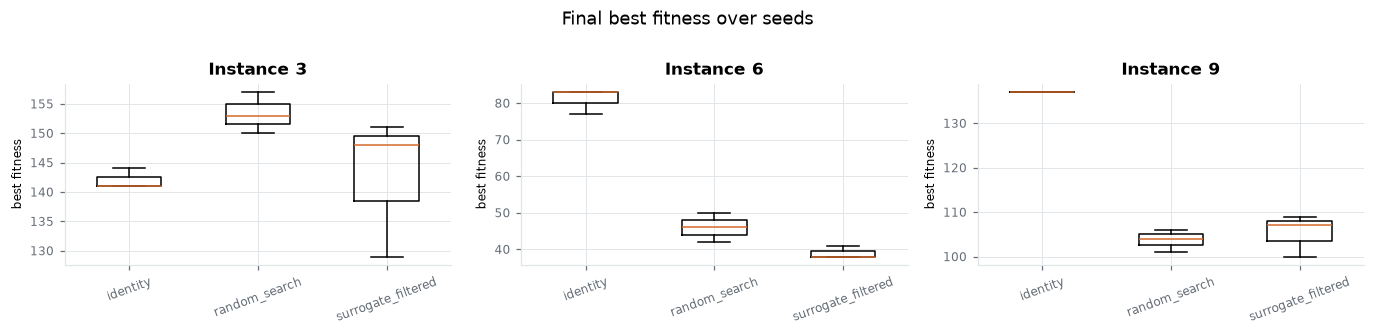

In [11]:
plot_result_boxplots(frame);

## 4. Sauvegarder et visualiser

- `save_results` enregistre toutes les exécutions (avec leur historique) dans `results/`, pour les recharger plus tard avec `load_results`.
- `write_result_if_better` écrit le meilleur placement au format du rendu (`GroupeX_Challenge_N.txt` : placement puis coût) dans `solutions/`, **seulement s'il est meilleur** que la solution déjà enregistrée. Le visualiseur web lit ce dossier, et le notebook `00_instance_explorer` peut l'afficher (`MAPPING = [...]`).

In [12]:
# Sauvegarde de toutes les exécutions dans results/.
save_results(results, RESULTS_ROOT / "template_demo.jsonl")
for instance_id in INSTANCES:
    # Meilleure exécution sur cette instance, tous algorithmes et graines confondus.
    best = min((r for r in results if r.instance_id == instance_id), key=lambda r: r.best_cost)
    path, written, previous = write_result_if_better(best, group=GROUP)
    status = "written" if written else f"kept existing file (cost {previous:g} is not worse)"
    print(f"instance {instance_id}: {best.algorithm} found {best.best_cost} -> {path.name}: {status}")

instance 3: surrogate_filtered found 129 -> Groupe0_Challenge_3.txt: kept existing file (cost 122 is not worse)
instance 6: surrogate_filtered found 38 -> Groupe0_Challenge_6.txt: kept existing file (cost 25 is not worse)
instance 9: surrogate_filtered found 100 -> Groupe0_Challenge_9.txt: kept existing file (cost 51 is not worse)


## 5. Ajouter une métaheuristique au projet

1. Crée `optimizer/algorithms/my_metaheuristic.py` avec une variable `name = "my_metaheuristic"` et une fonction `run(problem, rng, **params)`.
2. Ajoute-la dans le dictionnaire `ALGORITHMS` de `optimizer/algorithms/__init__.py`.
3. Étudie-la dans son propre notebook, puis ajoute-la au dictionnaire `CONTENDERS` du notebook `99_comparison` pour la comparer à toutes les autres.